When Should an ML Model Refuse to Predict?

A Customer Churn Study Using Calibration and Selective Prediction

Can a machine learning model recognize when its prediction may be unreliable?

In this project, I analyze customer churn using the Telco Customer Churn dataset and explore three connected problems:

- Prediction: Can we identify customers likely to leave?
- Calibration: Do predicted probabilities reflect actual outcomes?
- Selective prediction: Can a model abstain on uncertain cases and send them for human review?

Rather than optimizing accuracy alone, this project examines the trade-off between prediction coverage, reliability, churn detection, and review workload.

Tools

Python · Pandas · NumPy · Scikit-learn · Statsmodels · Matplotlib · Seaborn

Project Workflow

1. Data cleaning and exploratory analysis
2. Logistic Regression and Random Forest baselines
3. Threshold selection and model evaluation
4. Probability calibration
5. Selective prediction and abstention
6. Statistical analysis of churn-associated factors
7. Business recommendations and limitations

In [31]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith((".csv", ".parquet", ".xlsx")):
            print(os.path.join(dirname, filename))
            

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [32]:
import pandas as pd
import numpy as np

path = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nTarget distribution:")
print(df["Churn"].value_counts())
print("\nTarget percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nData types:")
print(df.dtypes)


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Missing values:
Series([], dtype: int64)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Clean TotalCharges: blank strings become missing values
data = df.copy()
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Remove identifier and separate target
X = data.drop(columns=["customerID", "Churn"])
y = data["Churn"].map({"No": 0, "Yes": 1})

# 60% training, 20% calibration, 20% final test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_cal, X_test, y_cal, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Train:", X_train.shape, "| Churn rate:", round(y_train.mean(), 3))
print("Calibration:", X_cal.shape, "| Churn rate:", round(y_cal.mean(), 3))
print("Test:", X_test.shape, "| Churn rate:", round(y_test.mean(), 3))
print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nMissing TotalCharges after conversion:", data["TotalCharges"].isna().sum())


Train: (4225, 19) | Churn rate: 0.265
Calibration: (1409, 19) | Churn rate: 0.265
Test: (1409, 19) | Churn rate: 0.265

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing TotalCharges after conversion: 11


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    accuracy_score
)
from sklearn.base import clone
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_cal)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_cal, probabilities),
        "PR-AUC": average_precision_score(y_cal, probabilities),
        "Log Loss": log_loss(y_cal, probabilities),
        "Brier Score": brier_score_loss(y_cal, probabilities),
        "Accuracy": accuracy_score(y_cal, predictions)
    })

    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy
Model,,,,,
Logistic Regression,0.8593,0.6778,0.4846,0.1640,0.7488
Random Forest,0.8548,0.6676,0.4453,0.1463,0.7850


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get predictions from the selected model
chosen_model = fitted_models["Random Forest"]

cal_probs = chosen_model.predict_proba(X_cal)[:, 1]
test_probs = chosen_model.predict_proba(X_test)[:, 1]

# Choose a confidence threshold using calibration data only.
# A prediction is accepted when confidence >= threshold.
cal_confidence = np.maximum(cal_probs, 1 - cal_probs)

candidate_thresholds = np.arange(0.50, 0.96, 0.01)
threshold_results = []

for threshold in candidate_thresholds:
    accepted = cal_confidence >= threshold
    if accepted.sum() == 0:
        continue

    threshold_results.append({
        "Threshold": threshold,
        "Coverage": accepted.mean(),
        "Accuracy": accuracy_score(
            y_cal[accepted],
            (cal_probs[accepted] >= 0.5).astype(int)
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_cal[accepted],
            (cal_probs[accepted] >= 0.5).astype(int)
        ),
        "F1": f1_score(
            y_cal[accepted],
            (cal_probs[accepted] >= 0.5).astype(int),
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select a threshold that retains at least 60% of cases,
# maximizing balanced accuracy on the calibration set.
eligible = threshold_df[threshold_df["Coverage"] >= 0.60]

if len(eligible) == 0:
    chosen_threshold = 0.50
else:
    chosen_threshold = eligible.sort_values(
        ["Balanced Accuracy", "Coverage"],
        ascending=[False, False]
    ).iloc[0]["Threshold"]

print(f"Selected confidence threshold: {chosen_threshold:.2f}")

# Evaluate once on the untouched test set
test_confidence = np.maximum(test_probs, 1 - test_probs)
test_accepted = test_confidence >= chosen_threshold

test_predictions = (test_probs >= 0.5).astype(int)
accepted_predictions = test_predictions[test_accepted]
accepted_actual = y_test.to_numpy()[test_accepted]

summary = pd.DataFrame([
    {
        "Strategy": "Predict for everyone",
        "Coverage": 1.0,
        "Cases handled": len(y_test),
        "Accuracy": accuracy_score(y_test, test_predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, test_predictions
        ),
        "F1": f1_score(y_test, test_predictions, zero_division=0)
    },
    {
        "Strategy": "Abstain on uncertain cases",
        "Coverage": test_accepted.mean(),
        "Cases handled": int(test_accepted.sum()),
        "Accuracy": accuracy_score(
            accepted_actual, accepted_predictions
        ) if test_accepted.sum() else np.nan,
        "Balanced Accuracy": balanced_accuracy_score(
            accepted_actual, accepted_predictions
        ) if test_accepted.sum() else np.nan,
        "F1": f1_score(
            accepted_actual, accepted_predictions, zero_division=0
        ) if test_accepted.sum() else np.nan
    }
])

display(summary.round(4))

Selected confidence threshold: 0.71


,Strategy,Coverage,Cases handled,Accuracy,Balanced Accuracy,F1
0,Predict for everyone,1.000,1409,0.7651,0.7487,0.6173
1,Abstain on uncertain cases,0.621,875,0.8640,0.8362,0.7213


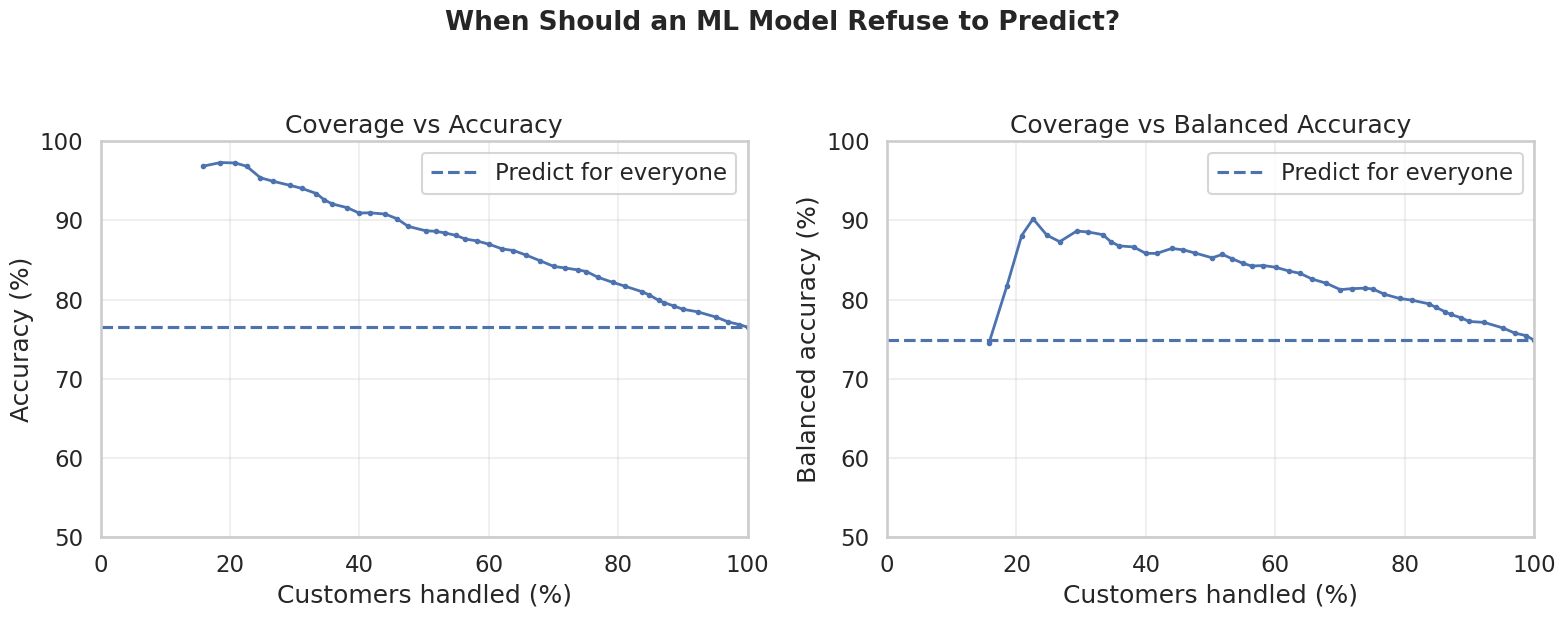

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, balanced_accuracy_score

sns.set_theme(style="whitegrid", context="talk")

# Evaluate a range of confidence thresholds on the test set.
# This curve is exploratory; use the calibration-selected threshold
# above for the primary held-out result.
thresholds = np.arange(0.50, 0.96, 0.01)
curve_results = []

for threshold in thresholds:
    accepted = test_confidence >= threshold

    if accepted.sum() == 0:
        continue

    preds = test_predictions[accepted]
    actual = y_test.to_numpy()[accepted]

    curve_results.append({
        "Threshold": threshold,
        "Coverage": accepted.mean(),
        "Accuracy": accuracy_score(actual, preds),
        "Balanced Accuracy": balanced_accuracy_score(actual, preds)
    })

curve_df = pd.DataFrame(curve_results).sort_values("Coverage")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(
    curve_df["Coverage"] * 100,
    curve_df["Accuracy"] * 100,
    marker="o",
    markersize=3,
    linewidth=2
)
axes[0].axhline(
    accuracy_score(y_test, test_predictions) * 100,
    linestyle="--",
    label="Predict for everyone"
)
axes[0].set_title("Coverage vs Accuracy")
axes[0].set_xlabel("Customers handled (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()

axes[1].plot(
    curve_df["Coverage"] * 100,
    curve_df["Balanced Accuracy"] * 100,
    marker="o",
    markersize=3,
    linewidth=2
)
axes[1].axhline(
    balanced_accuracy_score(y_test, test_predictions) * 100,
    linestyle="--",
    label="Predict for everyone"
)
axes[1].set_title("Coverage vs Balanced Accuracy")
axes[1].set_xlabel("Customers handled (%)")
axes[1].set_ylabel("Balanced accuracy (%)")
axes[1].legend()

for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_ylim(50, 100)
    ax.grid(alpha=0.3)

plt.suptitle(
    "When Should an ML Model Refuse to Predict?",
    fontsize=19,
    fontweight="bold",
    y=1.04
)
plt.tight_layout()
plt.show()

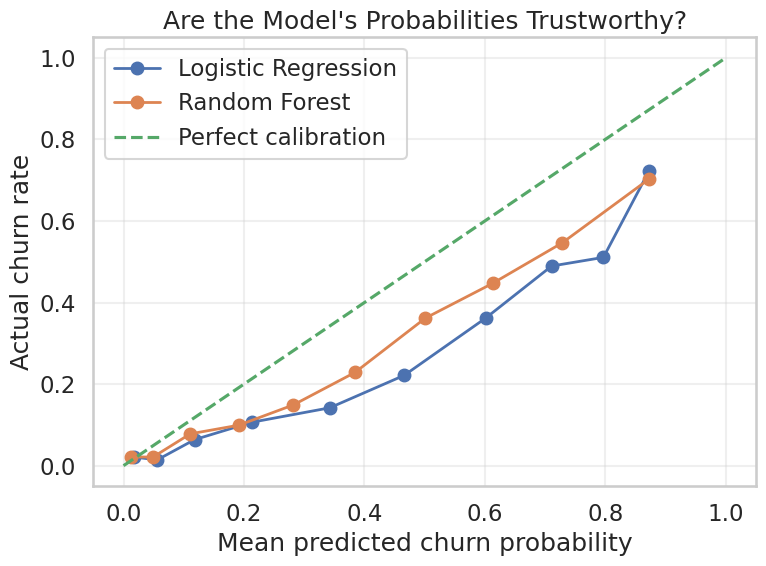

,Brier Score,Log Loss
Model,,
Logistic Regression,0.1732,0.5100
Random Forest,0.1581,0.4789


In [37]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
import matplotlib.pyplot as plt
import numpy as np

# Compare predicted churn probabilities with actual outcomes
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in fitted_models.items():
    probs = model.predict_proba(X_test)[:, 1]

    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        probs,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        linewidth=2,
        label=name
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set(
    title="Are the Model's Probabilities Trustworthy?",
    xlabel="Mean predicted churn probability",
    ylabel="Actual churn rate"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Probability quality comparison
calibration_results = []

for name, model in fitted_models.items():
    probs = model.predict_proba(X_test)[:, 1]

    calibration_results.append({
        "Model": name,
        "Brier Score": brier_score_loss(y_test, probs),
        "Log Loss": log_loss(y_test, probs)
    })

display(pd.DataFrame(calibration_results).set_index("Model").round(4))

,Model,Brier Score,Log Loss
0,Original Random Forest,0.1581,0.4789
1,Calibrated Random Forest,0.1430,0.4416


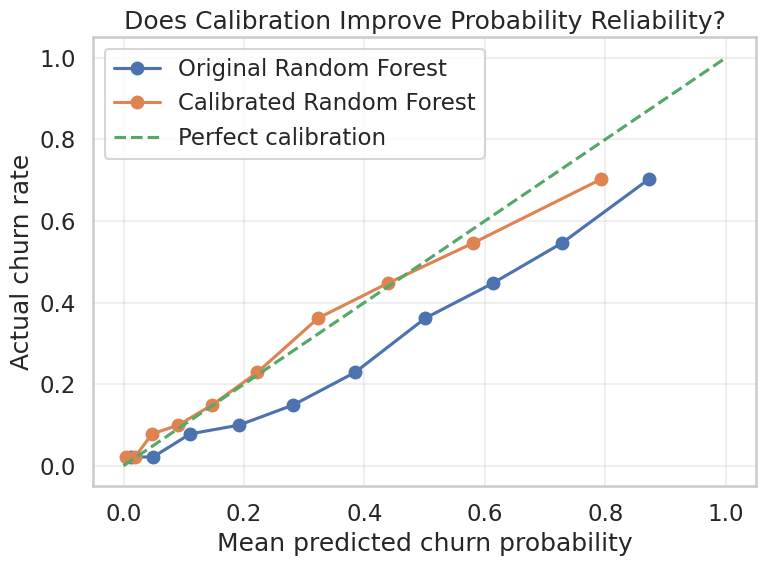

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Platt-style calibration using the calibration split
rf = fitted_models["Random Forest"]

cal_probs = rf.predict_proba(X_cal)[:, 1]
test_probs_original = rf.predict_proba(X_test)[:, 1]

# Fit calibration model on predicted probabilities from X_cal
eps = 1e-6
cal_logits = np.log(
    np.clip(cal_probs, eps, 1 - eps) /
    (1 - np.clip(cal_probs, eps, 1 - eps))
).reshape(-1, 1)

test_logits = np.log(
    np.clip(test_probs_original, eps, 1 - eps) /
    (1 - np.clip(test_probs_original, eps, 1 - eps))
).reshape(-1, 1)

probability_calibrator = LogisticRegression()
probability_calibrator.fit(cal_logits, y_cal)

test_probs_calibrated = probability_calibrator.predict_proba(
    test_logits
)[:, 1]

# Compare on the untouched test set
comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Calibrated Random Forest"],
    "Brier Score": [
        brier_score_loss(y_test, test_probs_original),
        brier_score_loss(y_test, test_probs_calibrated)
    ],
    "Log Loss": [
        log_loss(y_test, test_probs_original),
        log_loss(y_test, test_probs_calibrated)
    ]
})

display(comparison.round(4))

# Reliability diagram
plt.figure(figsize=(8, 6))

for label, probs in [
    ("Original Random Forest", test_probs_original),
    ("Calibrated Random Forest", test_probs_calibrated)
]:
    actual_rate, predicted_rate = calibration_curve(
        y_test, probs, n_bins=10, strategy="quantile"
    )
    plt.plot(predicted_rate, actual_rate, marker="o", label=label)

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean predicted churn probability")
plt.ylabel("Actual churn rate")
plt.title("Does Calibration Improve Probability Reliability?")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)
import numpy as np
import pandas as pd

# Calibrated probabilities for the calibration set
cal_logits = np.log(
    np.clip(cal_probs, 1e-6, 1 - 1e-6) /
    (1 - np.clip(cal_probs, 1e-6, 1 - 1e-6))
).reshape(-1, 1)

cal_probs_calibrated = probability_calibrator.predict_proba(
    cal_logits
)[:, 1]

# Confidence = probability assigned to the predicted class
cal_confidence_calibrated = np.maximum(
    cal_probs_calibrated, 1 - cal_probs_calibrated
)

threshold_results = []

for threshold in np.arange(0.50, 0.96, 0.01):
    accepted = cal_confidence_calibrated >= threshold

    if accepted.sum() < 50 or accepted.mean() < 0.60:
        continue

    preds = (cal_probs_calibrated[accepted] >= 0.5).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Coverage": accepted.mean(),
        "Balanced Accuracy": balanced_accuracy_score(
            y_cal.to_numpy()[accepted], preds
        )
    })

threshold_df_calibrated = pd.DataFrame(threshold_results)

chosen_threshold_calibrated = threshold_df_calibrated.sort_values(
    ["Balanced Accuracy", "Coverage"],
    ascending=[False, False]
).iloc[0]["Threshold"]

# Evaluate on untouched test set
test_confidence_calibrated = np.maximum(
    test_probs_calibrated, 1 - test_probs_calibrated
)
accepted = test_confidence_calibrated >= chosen_threshold_calibrated

all_preds = (test_probs_calibrated >= 0.5).astype(int)
accepted_preds = all_preds[accepted]
accepted_actual = y_test.to_numpy()[accepted]

final_comparison = pd.DataFrame([
    {
        "Strategy": "Calibrated model: all cases",
        "Coverage": 1.0,
        "Cases handled": len(y_test),
        "Accuracy": accuracy_score(y_test, all_preds),
        "Balanced Accuracy": balanced_accuracy_score(y_test, all_preds),
        "F1": f1_score(y_test, all_preds, zero_division=0)
    },
    {
        "Strategy": "Calibrated model: abstention",
        "Coverage": accepted.mean(),
        "Cases handled": int(accepted.sum()),
        "Accuracy": accuracy_score(accepted_actual, accepted_preds),
        "Balanced Accuracy": balanced_accuracy_score(
            accepted_actual, accepted_preds
        ),
        "F1": f1_score(accepted_actual, accepted_preds, zero_division=0)
    }
])

print("Chosen confidence threshold:", round(chosen_threshold_calibrated, 2))
display(final_comparison.round(4))

Chosen confidence threshold: 0.78


,Strategy,Coverage,Cases handled,Accuracy,Balanced Accuracy,F1
0,Calibrated model: all cases,1.0000,1409,0.7842,0.6832,0.5352
1,Calibrated model: abstention,0.6075,856,0.9007,0.7200,0.5729


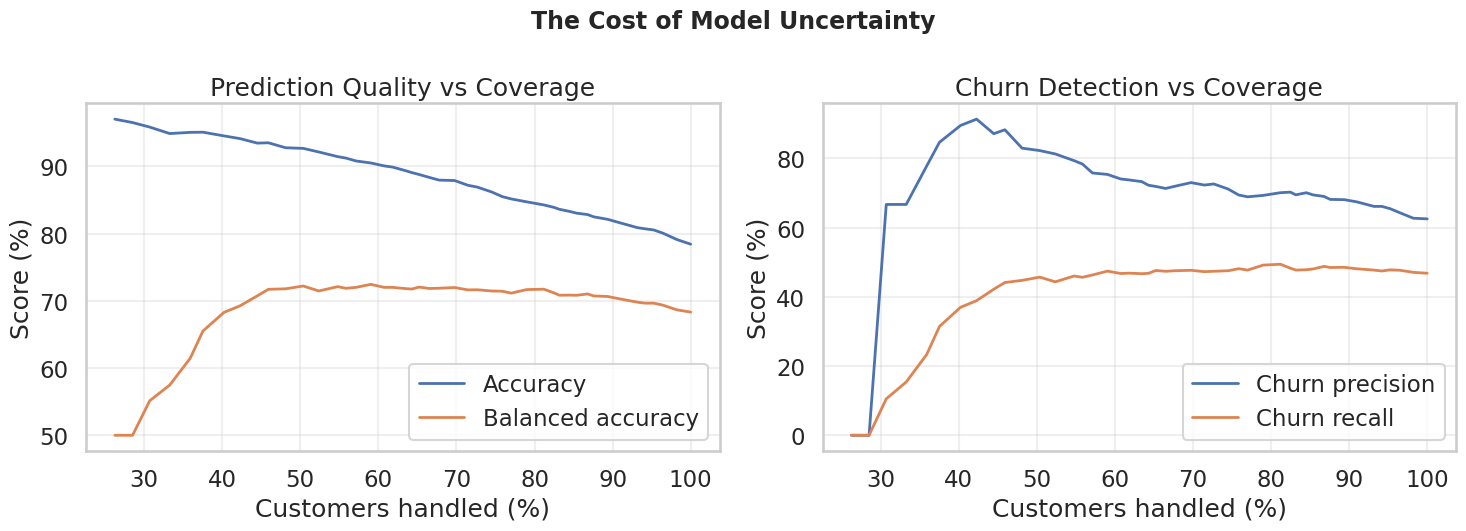

,Threshold,Coverage,Accuracy,Balanced Accuracy,Churn Precision,Churn Recall,F1
29,0.79,0.590,0.905,0.724,0.753,0.474,0.582
28,0.78,0.608,0.901,0.720,0.740,0.467,0.573
27,0.77,0.618,0.899,0.720,0.738,0.468,0.573
26,0.76,0.634,0.894,0.718,0.733,0.467,0.570
25,0.75,0.643,0.891,0.718,0.722,0.468,0.568


In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score
)

# Evaluate fixed confidence thresholds on the held-out test set
thresholds = np.arange(0.50, 0.96, 0.01)
rows = []

test_actual = y_test.to_numpy()
test_preds_cal = (test_probs_calibrated >= 0.5).astype(int)

for threshold in thresholds:
    accepted_mask = test_confidence_calibrated >= threshold

    if accepted_mask.sum() == 0:
        continue

    actual = test_actual[accepted_mask]
    pred = test_preds_cal[accepted_mask]

    rows.append({
        "Threshold": threshold,
        "Coverage": accepted_mask.mean(),
        "Accuracy": accuracy_score(actual, pred),
        "Balanced Accuracy": balanced_accuracy_score(actual, pred),
        "Churn Precision": precision_score(actual, pred, zero_division=0),
        "Churn Recall": recall_score(actual, pred, zero_division=0),
        "F1": f1_score(actual, pred, zero_division=0)
    })

selective_curve = pd.DataFrame(rows).sort_values("Coverage")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(
    selective_curve["Coverage"] * 100,
    selective_curve["Accuracy"] * 100,
    label="Accuracy",
    linewidth=2
)
axes[0].plot(
    selective_curve["Coverage"] * 100,
    selective_curve["Balanced Accuracy"] * 100,
    label="Balanced accuracy",
    linewidth=2
)
axes[0].set_title("Prediction Quality vs Coverage")
axes[0].set_xlabel("Customers handled (%)")
axes[0].set_ylabel("Score (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    selective_curve["Coverage"] * 100,
    selective_curve["Churn Precision"] * 100,
    label="Churn precision",
    linewidth=2
)
axes[1].plot(
    selective_curve["Coverage"] * 100,
    selective_curve["Churn Recall"] * 100,
    label="Churn recall",
    linewidth=2
)
axes[1].set_title("Churn Detection vs Coverage")
axes[1].set_xlabel("Customers handled (%)")
axes[1].set_ylabel("Score (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "The Cost of Model Uncertainty",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

display(selective_curve.iloc[
    (selective_curve["Coverage"] - accepted.mean()).abs().argsort()[:5]
].sort_values("Coverage").round(3))

,Measure,Value
0,Total customers,1409
1,Customers automatically classified,856
2,Customers sent for review,553
3,Coverage,60.8%
4,Actual churners,374
5,Churners automatically classified,122
6,Churners sent for review,252


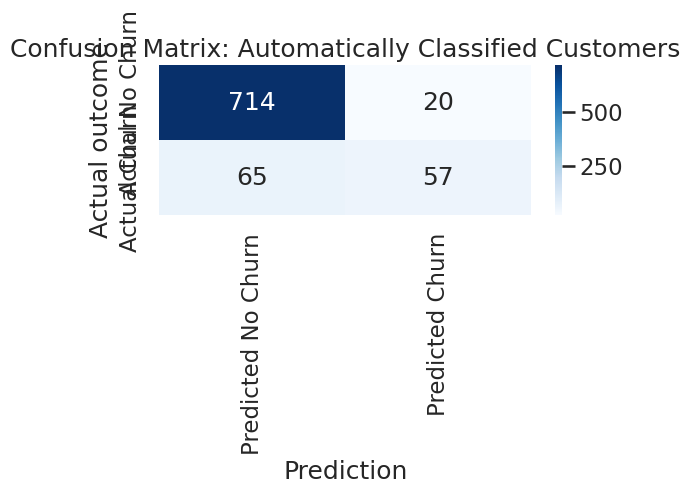

In [42]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions and accepted cases at the calibration-selected threshold
y_true = y_test.to_numpy()
y_pred = (test_probs_calibrated >= 0.5).astype(int)
accepted_mask = test_confidence_calibrated >= chosen_threshold_calibrated

# Accepted predictions
accepted_true = y_true[accepted_mask]
accepted_pred = y_pred[accepted_mask]

# Cases sent for review
review_mask = ~accepted_mask

actual_churners = y_true == 1

summary = pd.DataFrame({
    "Measure": [
        "Total customers",
        "Customers automatically classified",
        "Customers sent for review",
        "Coverage",
        "Actual churners",
        "Churners automatically classified",
        "Churners sent for review"
    ],
    "Value": [
        len(y_true),
        int(accepted_mask.sum()),
        int(review_mask.sum()),
        f"{accepted_mask.mean():.1%}",
        int(actual_churners.sum()),
        int(((y_true == 1) & accepted_mask).sum()),
        int(((y_true == 1) & review_mask).sum())
    ]
})

display(summary)

# Confusion matrix for automatically classified customers only
cm = confusion_matrix(accepted_true, accepted_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Churn", "Predicted Churn"],
    yticklabels=["Actual No Churn", "Actual Churn"]
)
plt.title("Confusion Matrix: Automatically Classified Customers")
plt.xlabel("Prediction")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.show()

In [43]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score
)
import numpy as np
import pandas as pd

y_true = y_test.to_numpy()

# Original model, threshold selected on calibration set
original_test_probs = fitted_models["Random Forest"].predict_proba(X_test)[:, 1]
original_test_conf = np.maximum(original_test_probs, 1 - original_test_probs)

original_cal_conf = np.maximum(cal_probs, 1 - cal_probs)
original_rows = []

for threshold in np.arange(0.50, 0.96, 0.01):
    mask = original_cal_conf >= threshold
    if mask.mean() < 0.60 or mask.sum() < 50:
        continue

    pred = (cal_probs[mask] >= 0.5).astype(int)
    original_rows.append({
        "Threshold": threshold,
        "Balanced Accuracy": balanced_accuracy_score(
            y_cal.to_numpy()[mask], pred
        ),
        "Coverage": mask.mean()
    })

original_threshold = pd.DataFrame(original_rows).sort_values(
    ["Balanced Accuracy", "Coverage"],
    ascending=[False, False]
).iloc[0]["Threshold"]

strategies = []

for name, probs, conf, threshold in [
    ("Original RF + abstention", original_test_probs, original_test_conf, original_threshold),
    ("Calibrated RF + abstention", test_probs_calibrated, test_confidence_calibrated, chosen_threshold_calibrated)
]:
    pred = (probs >= 0.5).astype(int)
    mask = conf >= threshold

    strategies.append({
        "Strategy": name,
        "Threshold": threshold,
        "Coverage": mask.mean(),
        "Accuracy on accepted": accuracy_score(y_true[mask], pred[mask]),
        "Balanced accuracy": balanced_accuracy_score(y_true[mask], pred[mask]),
        "Churn precision": precision_score(y_true[mask], pred[mask], zero_division=0),
        "Churn recall": recall_score(y_true[mask], pred[mask], zero_division=0),
        "F1": f1_score(y_true[mask], pred[mask], zero_division=0),
        "Churners sent to review": int(((y_true == 1) & ~mask).sum())
    })

display(pd.DataFrame(strategies).set_index("Strategy").round(4))

,Threshold,Coverage,Accuracy on accepted,Balanced accuracy,Churn precision,Churn recall,F1,Churners sent to review
Strategy,,,,,,,,
Original RF + abstention,0.71,0.6210,0.8640,0.8362,0.6667,0.7857,0.7213,178
Calibrated RF + abstention,0.78,0.6075,0.9007,0.7200,0.7403,0.4672,0.5729,252


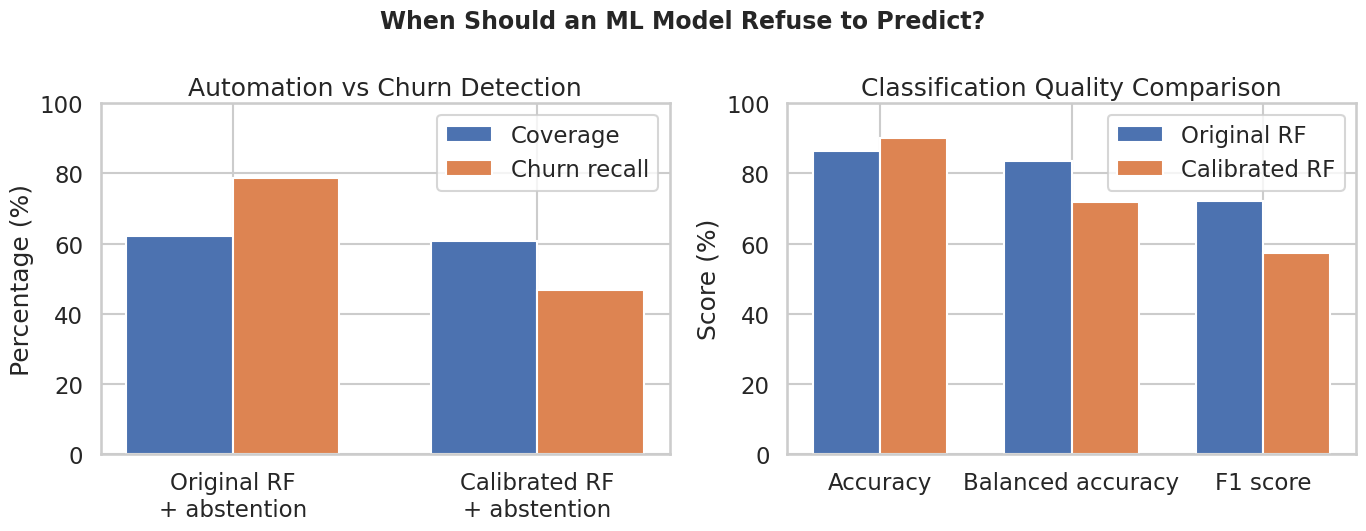

In [44]:
import matplotlib.pyplot as plt
import numpy as np

strategies = [
    "Original RF\n+ abstention",
    "Calibrated RF\n+ abstention"
]

metrics = {
    "Coverage": [0.6210, 0.6075],
    "Accuracy": [0.8640, 0.9007],
    "Balanced accuracy": [0.8362, 0.7200],
    "Churn recall": [0.7857, 0.4672],
    "F1 score": [0.7213, 0.5729]
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Operational trade-off
x = np.arange(2)
width = 0.35

axes[0].bar(
    x - width / 2,
    np.array(metrics["Coverage"]) * 100,
    width,
    label="Coverage"
)
axes[0].bar(
    x + width / 2,
    np.array(metrics["Churn recall"]) * 100,
    width,
    label="Churn recall"
)
axes[0].set_xticks(x, strategies)
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title("Automation vs Churn Detection")
axes[0].legend()
axes[0].set_ylim(0, 100)

# Classification quality
quality_metrics = ["Accuracy", "Balanced accuracy", "F1 score"]
x = np.arange(len(quality_metrics))
width = 0.35

axes[1].bar(
    x - width / 2,
    [metrics[m][0] * 100 for m in quality_metrics],
    width,
    label="Original RF"
)
axes[1].bar(
    x + width / 2,
    [metrics[m][1] * 100 for m in quality_metrics],
    width,
    label="Calibrated RF"
)
axes[1].set_xticks(x, quality_metrics)
axes[1].set_ylabel("Score (%)")
axes[1].set_title("Classification Quality Comparison")
axes[1].legend()
axes[1].set_ylim(0, 100)

fig.suptitle(
    "When Should an ML Model Refuse to Predict?",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

In [46]:
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# Baseline and model candidates
baseline_models = {
    "Majority Class Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

baseline_results = []

for name, estimator in baseline_models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    # Evaluate on the test set
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities),
        "Log Loss": log_loss(y_test, probabilities)
    })

baseline_df = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_df.round(4))

,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score,Log Loss
Model,,,,,,,,,
Majority Class Baseline,0.7346,0.5000,0.0000,0.0000,0.0000,0.5000,0.2654,0.2654,9.5673
Logistic Regression,0.7417,0.7635,0.5084,0.8102,0.6247,0.8321,0.6232,0.1732,0.5100
Random Forest,0.7651,0.7487,0.5438,0.7139,0.6173,0.8270,0.6191,0.1581,0.4789


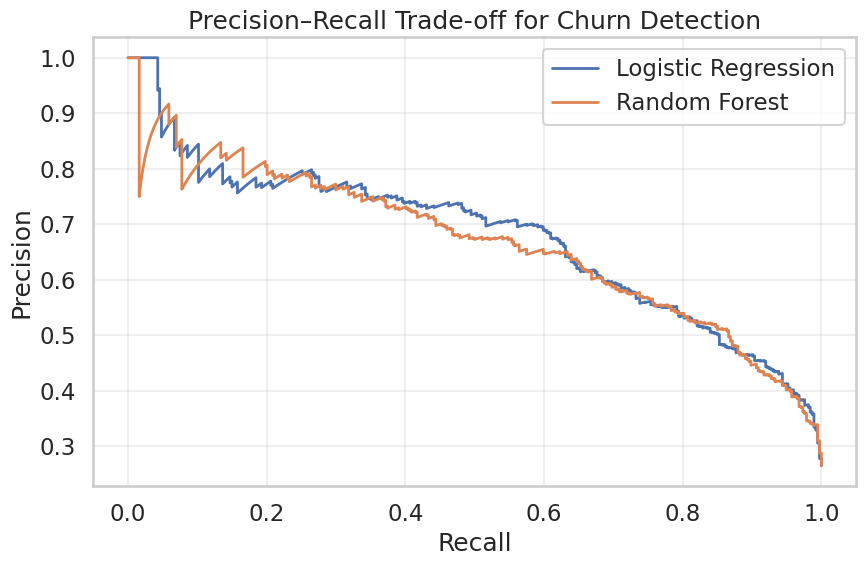

,Model,Threshold,Precision,Recall,F1
23,Logistic Regression,0.56,0.5451,0.7914,0.6456
59,Random Forest,0.46,0.5463,0.7888,0.6455


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Use the existing fitted models and calibration split
threshold_results = []
threshold_curves = {}

for name in ["Logistic Regression", "Random Forest"]:
    model = fitted_models[name]
    probs = model.predict_proba(X_cal)[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_cal, probs)

    # Store curve for visualization
    threshold_curves[name] = (precision, recall, thresholds)

    # Evaluate thresholds on calibration data
    rows = []

    for threshold in np.arange(0.10, 0.91, 0.02):
        pred = (probs >= threshold).astype(int)

        p = precision_score(y_cal, pred, zero_division=0)
        r = recall_score(y_cal, pred, zero_division=0)
        f1 = f1_score(y_cal, pred, zero_division=0)

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": p,
            "Recall": r,
            "F1": f1
        })

    threshold_results.extend(rows)

threshold_df = pd.DataFrame(threshold_results)

# Visualize precision-recall trade-off
plt.figure(figsize=(9, 6))

for name, (precision, recall, thresholds) in threshold_curves.items():
    plt.plot(recall, precision, linewidth=2, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Trade-off for Churn Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Best F1 threshold on calibration data for each model
best_thresholds = (
    threshold_df.sort_values("F1", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("Model")
)

display(best_thresholds.round(4))

In [48]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

selected_thresholds = {
    "Logistic Regression": 0.56,
    "Random Forest": 0.46
}

test_threshold_results = []

for name, threshold in selected_thresholds.items():
    model = fitted_models[name]
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= threshold).astype(int)

    test_threshold_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, preds),
        "Balanced Accuracy": balanced_accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probs),
        "PR-AUC": average_precision_score(y_test, probs)
    })

test_threshold_df = pd.DataFrame(test_threshold_results).set_index("Model")
display(test_threshold_df.round(4))

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,,
Logistic Regression,0.56,0.7587,0.7589,0.5318,0.7594,0.6256,0.8321,0.6232
Random Forest,0.46,0.7537,0.7598,0.5245,0.7727,0.6249,0.8270,0.6191


,Customers
Outcome,
Correct Prediction,1069
False Churn Alert,250
Missed Churner,90


Error_Type,Correct Prediction,False Churn Alert,Missed Churner
Contract,,,
Month-to-month,63.4,30.8,5.9
One year,86.6,2.8,10.6
Two year,95.9,0.0,4.1


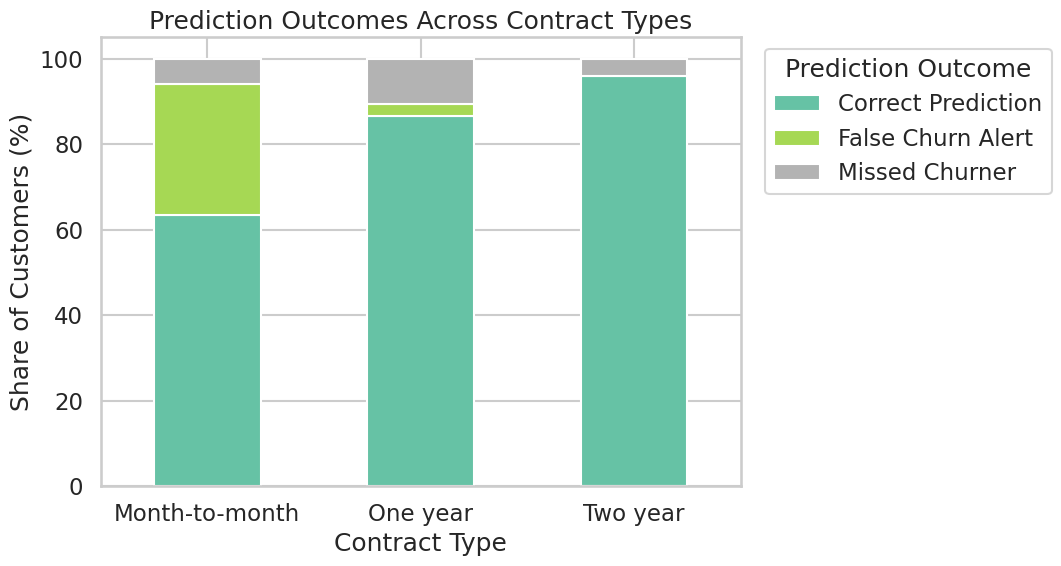

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Test-set predictions from tuned Logistic Regression
lr_model = fitted_models["Logistic Regression"]
test_probs_lr = lr_model.predict_proba(X_test)[:, 1]
test_preds_lr = (test_probs_lr >= 0.56).astype(int)

# Build an analysis table from original, unprocessed test features
error_df = X_test.copy()
error_df["Actual_Churn"] = y_test.to_numpy()
error_df["Predicted_Churn"] = test_preds_lr
error_df["Predicted_Probability"] = test_probs_lr

error_df["Error_Type"] = np.select(
    [
        (error_df["Actual_Churn"] == 1) &
        (error_df["Predicted_Churn"] == 0),

        (error_df["Actual_Churn"] == 0) &
        (error_df["Predicted_Churn"] == 1)
    ],
    [
        "Missed Churner",
        "False Churn Alert"
    ],
    default="Correct Prediction"
)

display(
    error_df["Error_Type"]
    .value_counts()
    .rename_axis("Outcome")
    .to_frame("Customers")
)

# Compare churn rates by contract type and error outcome
contract_error = pd.crosstab(
    error_df["Contract"],
    error_df["Error_Type"],
    normalize="index"
) * 100

display(contract_error.round(1))

# Visualize error types by contract
contract_error.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="Set2"
)

plt.title("Prediction Outcomes Across Contract Types")
plt.xlabel("Contract Type")
plt.ylabel("Share of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Prediction Outcome", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Average customer characteristics by prediction outcome


,tenure,MonthlyCharges,TotalCharges
Error_Type,,,
Correct Prediction,35.36,61.63,2358.69
False Churn Alert,19.89,76.40,1704.91
Missed Churner,33.02,66.34,2777.68


Actual churn rate by contract type


Churn,Churn,No Churn
Contract,,
Month-to-month,41.2,58.8
One year,12.7,87.3
Two year,4.1,95.9


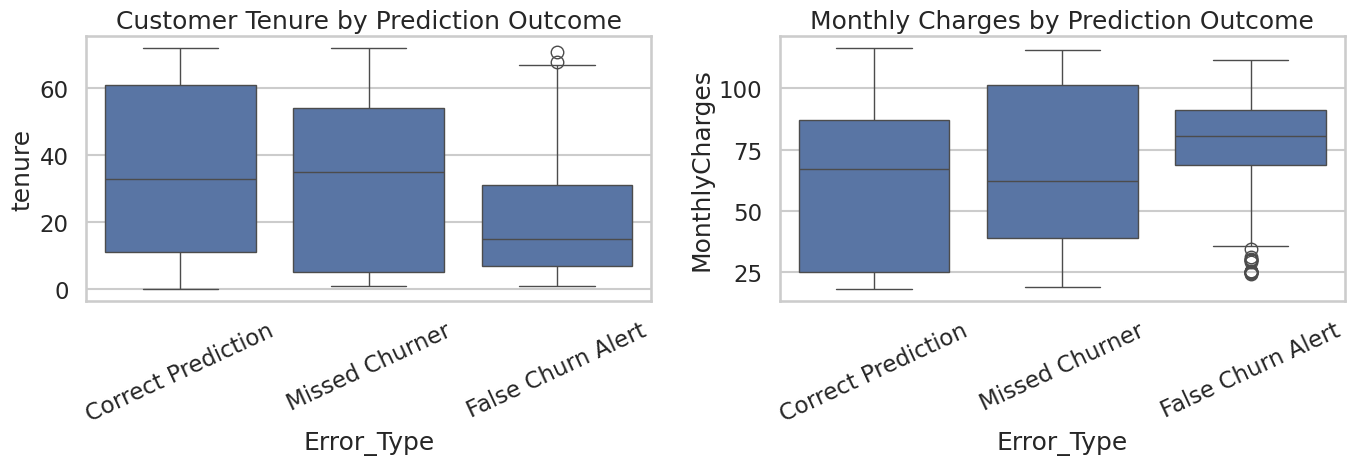

In [50]:
# Compare customer characteristics across prediction outcomes

error_groups = error_df.groupby("Error_Type")

numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Average customer characteristics by prediction outcome")
display(error_groups[numeric_cols].mean().round(2))

print("Actual churn rate by contract type")
contract_churn = pd.crosstab(
    X_test["Contract"],
    y_test.map({0: "No Churn", 1: "Churn"}),
    normalize="index"
) * 100

display(contract_churn.round(1))

# Compare tenure and monthly charges for each error group
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=error_df,
    x="Error_Type",
    y="tenure",
    ax=axes[0]
)
axes[0].set_title("Customer Tenure by Prediction Outcome")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=error_df,
    x="Error_Type",
    y="MonthlyCharges",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges by Prediction Outcome")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

,Feature,Importance,Std
4,tenure,0.1826,0.0082
14,Contract,0.0429,0.0061
7,InternetService,0.0354,0.0086
18,TotalCharges,0.0290,0.0085
11,TechSupport,0.0148,0.0023
17,MonthlyCharges,0.0112,0.0094
16,PaymentMethod,0.0092,0.0050
8,OnlineSecurity,0.0078,0.0022
12,StreamingTV,0.0060,0.0029
13,StreamingMovies,0.0041,0.0012


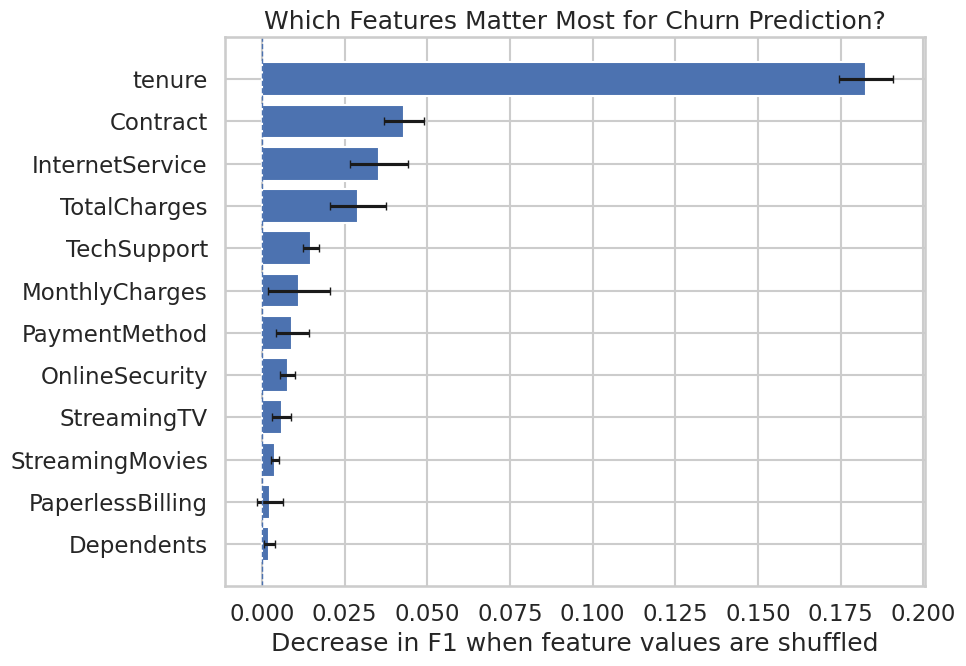

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

# Use the tuned Logistic Regression model
lr_model = fitted_models["Logistic Regression"]

# Permutation importance on the untouched test set
# F1 is used to measure impact on churn classification
importance = permutation_importance(
    lr_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(12).round(4))

# Visualize the top 12 features
top_features = importance_df.head(12).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"],
    capsize=3
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.title("Which Features Matter Most for Churn Prediction?")
plt.xlabel("Decrease in F1 when feature values are shuffled")
plt.ylabel("")
plt.tight_layout()
plt.show()

,Customers,Churners,ChurnRate
TenureGroup,,,
0–6,1481,784,52.94
7–12,705,253,35.89
13–24,1024,294,28.71
25–48,1594,325,20.39
49–72,2239,213,9.51


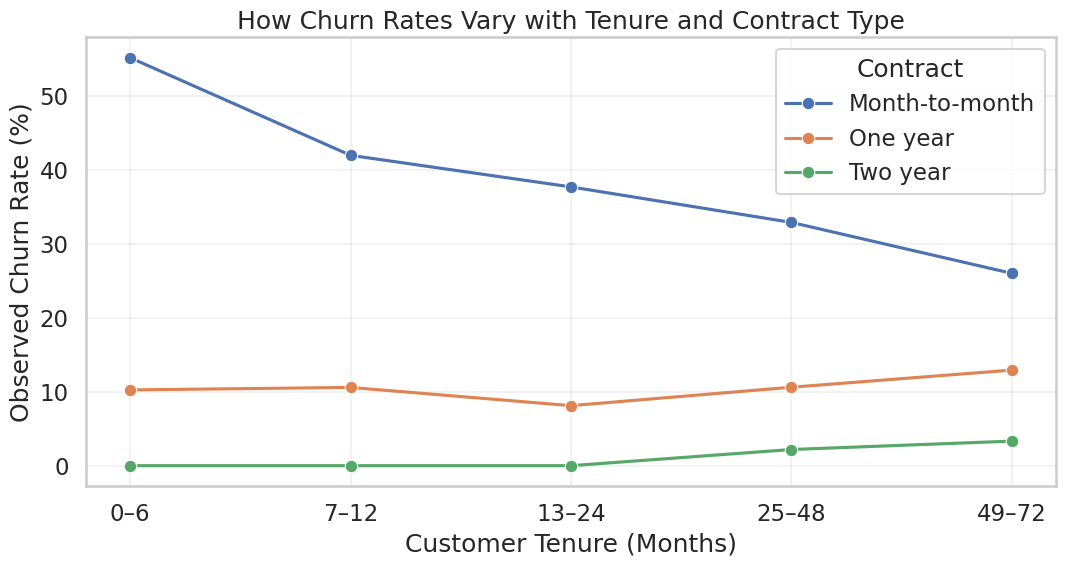

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use the original dataset, not the test set
analysis_df = df.copy()

analysis_df["TotalCharges"] = pd.to_numeric(
    analysis_df["TotalCharges"], errors="coerce"
)
analysis_df["ChurnFlag"] = analysis_df["Churn"].map(
    {"No": 0, "Yes": 1}
)

# Create tenure groups
analysis_df["TenureGroup"] = pd.cut(
    analysis_df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6", "7–12", "13–24", "25–48", "49–72"]
)

# Churn rate and sample size for each tenure group
tenure_summary = (
    analysis_df.groupby("TenureGroup", observed=False)
    .agg(
        Customers=("ChurnFlag", "size"),
        Churners=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean")
    )
)

tenure_summary["ChurnRate"] *= 100
display(tenure_summary.round(2))

# Churn rate by tenure group and contract type
contract_tenure = (
    analysis_df.groupby(
        ["TenureGroup", "Contract"], observed=False
    )["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index(name="ChurnRate")
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=contract_tenure,
    x="TenureGroup",
    y="ChurnRate",
    hue="Contract",
    marker="o"
)

plt.title("How Churn Rates Vary with Tenure and Contract Type")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Observed Churn Rate (%)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [53]:
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def test_association(data, feature, target="ChurnFlag"):
    table = pd.crosstab(data[feature], data[target])
    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    rows, cols = table.shape
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    return {
        "Feature": feature,
        "Chi-square": chi2,
        "Degrees of freedom": dof,
        "P-value": p_value,
        "Cramer's V": cramers_v
    }

# Statistical association tests
association_results = pd.DataFrame([
    test_association(analysis_df, "TenureGroup"),
    test_association(analysis_df, "Contract")
])

display(association_results.round(6))

# Show sample sizes behind the contract-tenure chart
sample_counts = pd.crosstab(
    analysis_df["TenureGroup"],
    analysis_df["Contract"]
)

display(sample_counts)

,Feature,Chi-square,Degrees of freedom,P-value,Cramer's V
0,TenureGroup,927.329275,4,0.0,0.362859
1,Contract,1184.596572,2,0.0,0.410116


Contract,Month-to-month,One year,Two year
TenureGroup,,,
0–6,1413,39,29
7–12,581,85,39
13–24,737,197,90
25–48,802,518,274
49–72,342,634,1263


,TenureGroup,Contract,Customers,Churners,ChurnRate
0,0–6,Month-to-month,1413,780,55.20
1,0–6,One year,39,4,10.26
2,0–6,Two year,29,0,0.00
3,7–12,Month-to-month,581,244,42.00
4,7–12,One year,85,9,10.59
5,7–12,Two year,39,0,0.00
6,13–24,Month-to-month,737,278,37.72
7,13–24,One year,197,16,8.12
8,13–24,Two year,90,0,0.00
9,25–48,Month-to-month,802,264,32.92


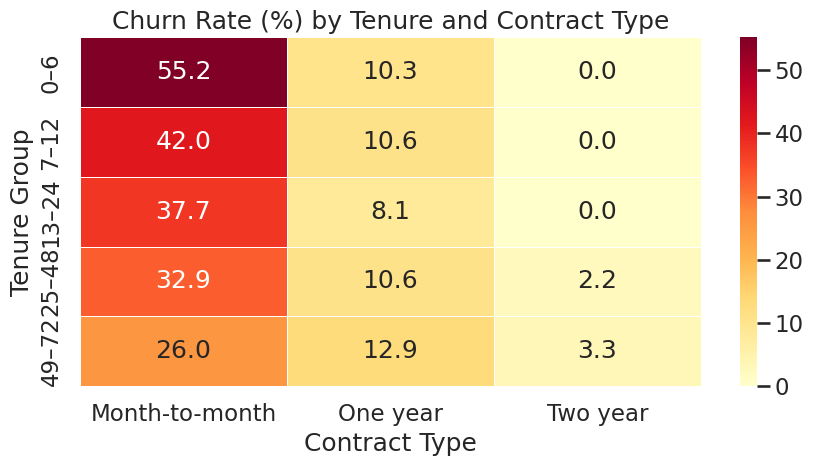

Customer counts for interpreting the heatmap:


Contract,Month-to-month,One year,Two year
TenureGroup,,,
0–6,1413,39,29
7–12,581,85,39
13–24,737,197,90
25–48,802,518,274
49–72,342,634,1263


In [54]:
# Churn rate and customer count for each combination
segment_analysis = (
    analysis_df.groupby(
        ["TenureGroup", "Contract"],
        observed=False
    )
    .agg(
        Customers=("ChurnFlag", "size"),
        Churners=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean")
    )
    .reset_index()
)

segment_analysis["ChurnRate"] *= 100

display(
    segment_analysis
    .sort_values(["TenureGroup", "Contract"])
    .round(2)
)

# Heatmap of observed churn rates
rate_pivot = segment_analysis.pivot(
    index="TenureGroup",
    columns="Contract",
    values="ChurnRate"
)

count_pivot = segment_analysis.pivot(
    index="TenureGroup",
    columns="Contract",
    values="Customers"
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    rate_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)
plt.title("Churn Rate (%) by Tenure and Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Group")
plt.tight_layout()
plt.show()

print("Customer counts for interpreting the heatmap:")
display(count_pivot)

In [55]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

def association_test(data, feature):
    table = pd.crosstab(data[feature], data["ChurnFlag"])
    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    r, c = table.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

    return {
        "Feature": feature,
        "Chi-square": chi2,
        "P-value": p,
        "Cramer's V": cramers_v
    }

results = pd.DataFrame([
    association_test(analysis_df, "TenureGroup"),
    association_test(analysis_df, "Contract")
])

display(results.round(6))

,Feature,Chi-square,P-value,Cramer's V
0,TenureGroup,927.329275,0.0,0.362859
1,Contract,1184.596572,0.0,0.410116


In [56]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

reg_df = df.copy()

reg_df["TotalCharges"] = pd.to_numeric(
    reg_df["TotalCharges"], errors="coerce"
)
reg_df["ChurnFlag"] = reg_df["Churn"].map({"No": 0, "Yes": 1})

# Combine equivalent service-status categories
service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in service_cols:
    reg_df[col] = reg_df[col].replace("No internet service", "No")

reg_df = reg_df.dropna(
    subset=[
        "ChurnFlag", "tenure", "MonthlyCharges",
        "Contract", "InternetService", "TechSupport",
        "SeniorCitizen", "Partner", "Dependents"
    ]
)

formula = (
    "ChurnFlag ~ tenure + MonthlyCharges + C(Contract) "
    "+ C(InternetService) + C(TechSupport) "
    "+ SeniorCitizen + C(Partner) + C(Dependents)"
)

model_fixed = smf.logit(formula, data=reg_df).fit(
    disp=False, maxiter=200
)

conf = model_fixed.conf_int()

odds_results_fixed = pd.DataFrame({
    "Odds Ratio": np.exp(model_fixed.params),
    "CI Lower": np.exp(conf[0]),
    "CI Upper": np.exp(conf[1]),
    "P-value": model_fixed.pvalues
})

display(odds_results_fixed.round(4))
print("Pseudo R-squared:", round(model_fixed.prsquared, 4))
print("Observations:", int(model_fixed.nobs))

,Odds Ratio,CI Lower,CI Upper,P-value
Intercept,0.5254,0.3841,0.7185,0.0001
C(Contract)[T.One year],0.4637,0.3780,0.5688,0.0000
C(Contract)[T.Two year],0.2198,0.1569,0.3080,0.0000
C(InternetService)[T.Fiber optic],2.1236,1.6305,2.7658,0.0000
C(InternetService)[T.No],0.4223,0.3143,0.5673,0.0000
C(TechSupport)[T.Yes],0.6492,0.5475,0.7697,0.0000
C(Partner)[T.Yes],1.0197,0.8782,1.1840,0.7980
C(Dependents)[T.Yes],0.7995,0.6726,0.9503,0.0111
tenure,0.9675,0.9634,0.9716,0.0000
MonthlyCharges,1.0095,1.0033,1.0158,0.0028


Pseudo R-squared: 0.2628
Observations: 7043


,Coefficient,Odds Ratio,CI Lower,CI Upper,P-value
Factor,,,,,
One-year contract,-0.7686,0.4637,0.3780,0.5688,0.0000
Two-year contract,-1.5149,0.2198,0.1569,0.3080,0.0000
Fiber optic internet,0.7531,2.1236,1.6305,2.7658,0.0000
No internet service,-0.8621,0.4223,0.3143,0.5673,0.0000
Tech support: Yes,-0.4321,0.6492,0.5475,0.7697,0.0000
Dependents: Yes,-0.2238,0.7995,0.6726,0.9503,0.0111
Tenure (per month),-0.0330,0.9675,0.9634,0.9716,0.0000
Monthly charges,0.0095,1.0095,1.0033,1.0158,0.0028
Senior citizen,0.3165,1.3723,1.1661,1.6149,0.0001


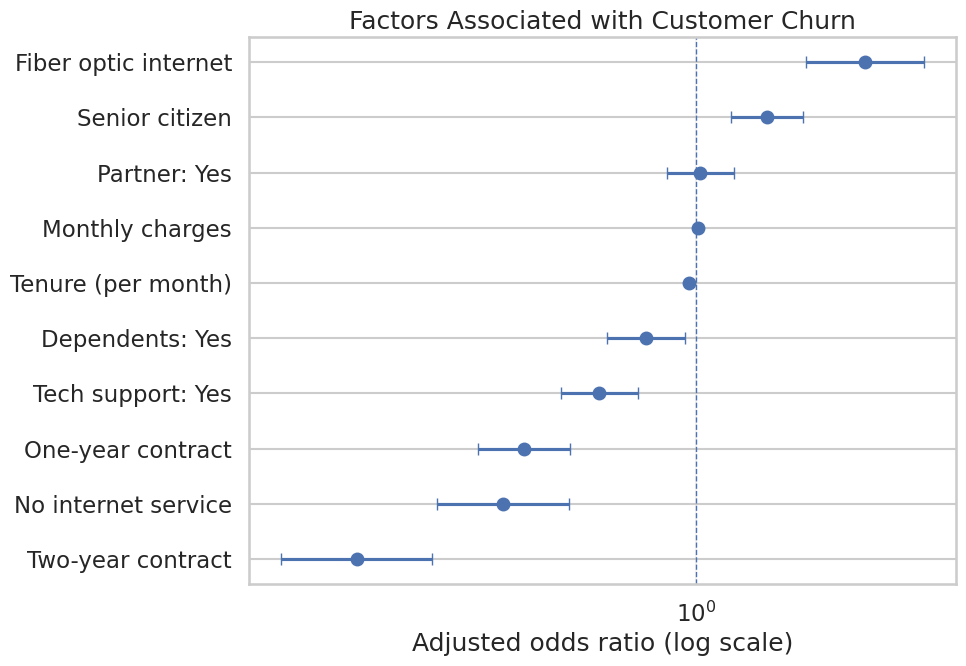

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recreate diagnostics from the fitted regression model
conf = model_fixed.conf_int()

diagnostics = pd.DataFrame({
    "Coefficient": model_fixed.params,
    "Odds Ratio": np.exp(model_fixed.params),
    "CI Lower": np.exp(conf[0]),
    "CI Upper": np.exp(conf[1]),
    "P-value": model_fixed.pvalues
})

key_terms = [
    "C(Contract)[T.One year]",
    "C(Contract)[T.Two year]",
    "C(InternetService)[T.Fiber optic]",
    "C(InternetService)[T.No]",
    "C(TechSupport)[T.Yes]",
    "C(Dependents)[T.Yes]",
    "tenure",
    "MonthlyCharges",
    "SeniorCitizen",
    "C(Partner)[T.Yes]"
]

labels = [
    "One-year contract",
    "Two-year contract",
    "Fiber optic internet",
    "No internet service",
    "Tech support: Yes",
    "Dependents: Yes",
    "Tenure (per month)",
    "Monthly charges",
    "Senior citizen",
    "Partner: Yes"
]

summary = diagnostics.loc[key_terms].copy()
summary.index = labels
summary.index.name = "Factor"

display(summary.round(4))

# Plot adjusted odds ratios with confidence intervals
plot_df = summary.sort_values("Odds Ratio")

plt.figure(figsize=(10, 7))

plt.errorbar(
    plot_df["Odds Ratio"],
    plot_df.index,
    xerr=[
        plot_df["Odds Ratio"] - plot_df["CI Lower"],
        plot_df["CI Upper"] - plot_df["Odds Ratio"]
    ],
    fmt="o",
    capsize=4
)

plt.axvline(1, linestyle="--", linewidth=1)
plt.xscale("log")
plt.xlabel("Adjusted odds ratio (log scale)")
plt.title("Factors Associated with Customer Churn")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [58]:
import pandas as pd
import numpy as np

final_findings = pd.DataFrame({
    "Finding": [
        "Highest-risk tenure group",
        "Lowest-risk tenure group",
        "Two-year contract",
        "One-year contract",
        "Fiber-optic internet",
        "Tenure effect",
        "Partner status"
    ],
    "Result": [
        "0–6 months: 52.94% churn",
        "49–72 months: 9.51% churn",
        "Adjusted churn odds ~78% lower",
        "Adjusted churn odds ~54% lower",
        "Adjusted odds ~2.12x reference category",
        "~3.25% lower odds per additional month",
        "Not statistically significant (p = 0.798)"
    ]
})

display(final_findings)

,Finding,Result
0,Highest-risk tenure group,0–6 months: 52.94% churn
1,Lowest-risk tenure group,49–72 months: 9.51% churn
2,Two-year contract,Adjusted churn odds ~78% lower
3,One-year contract,Adjusted churn odds ~54% lower
4,Fiber-optic internet,Adjusted odds ~2.12x reference category
5,Tenure effect,~3.25% lower odds per additional month
6,Partner status,Not statistically significant (p = 0.798)


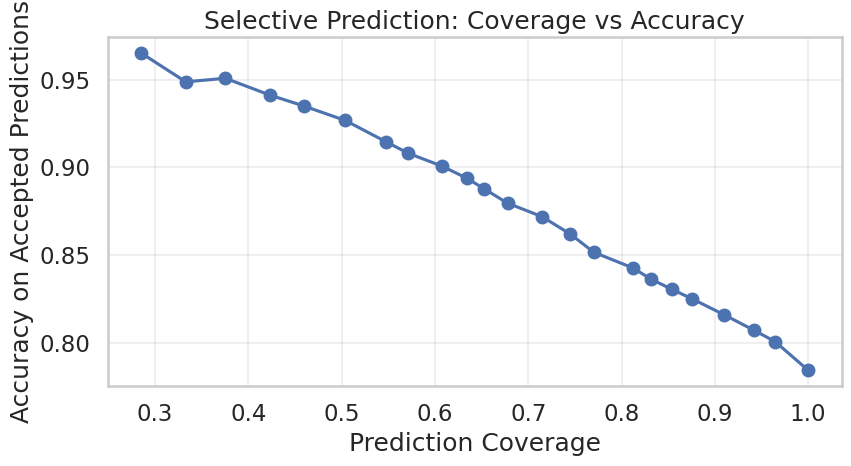

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

probs = np.asarray(test_probs_calibrated)
y_true = np.asarray(y_test)

thresholds = np.arange(0.50, 0.96, 0.02)

coverages = []
selective_accuracies = []

confidence = np.maximum(probs, 1 - probs)
predictions = (probs >= 0.5).astype(int)

for threshold in thresholds:
    accepted = confidence >= threshold

    coverage = accepted.mean()
    accuracy = (
        accuracy_score(y_true[accepted], predictions[accepted])
        if accepted.sum() > 0 else np.nan
    )

    coverages.append(coverage)
    selective_accuracies.append(accuracy)

plt.figure(figsize=(9, 5))

plt.plot(
    coverages,
    selective_accuracies,
    marker="o"
)

plt.xlabel("Prediction Coverage")
plt.ylabel("Accuracy on Accepted Predictions")
plt.title("Selective Prediction: Coverage vs Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Key Findings & Business Recommendations

1. Customer churn is concentrated among newer customers

Customers in their first 6 months have a 52.94% churn rate, compared with 9.51% among customers with 49–72 months of tenure.

Recommendation: Prioritize onboarding, early engagement, and retention offers during the first six months.

2. Contract type is strongly associated with churn

After adjusting for other variables in the logistic regression model, one-year contracts have approximately 54% lower churn odds, while two-year contracts have approximately 78% lower churn odds than month-to-month contracts.

Recommendation: Test flexible incentives that encourage customers to consider longer-term plans without creating unnecessary discounts.

3. Internet service and support matter

Fiber-optic customers have approximately 2.12 times the adjusted churn odds of customers in the reference internet-service category. Customers with tech support have approximately 35% lower adjusted churn odds than customers without it.

Recommendation: Investigate fiber customers’ pricing, service quality, and support experience before designing targeted retention strategies.

4. Prediction confidence is not the same as prediction quality

Probability calibration improved the Random Forest model's Brier score from 0.1581 to 0.1430 on the test set. However, the calibrated model's abstention strategy detected fewer churners among the customers it chose to predict.

Recommendation: Choose the model's confidence threshold based on the business cost of missed churners, false alerts, and manual reviews—not accuracy alone.

Limitations

These results come from a historical Telco customer dataset. Associations do not establish causation, and model performance may change with new customers or changing business conditions. The test set was also used for exploratory comparisons, so final performance claims should be validated using an untouched holdout set or nested cross-validation.

Conclusion

This project explores more than predicting customer churn. It examines how probability calibration and selective prediction can help determine when a model should make a prediction and when it should defer to human review.

In [60]:
import os
import glob
import zipfile
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

# Folder for graph images
folder = "/kaggle/working/graph_gallery"
os.makedirs(folder, exist_ok=True)

# Save any matplotlib figures still available
for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        os.path.join(folder, f"graph_{i}.png"),
        dpi=200,
        bbox_inches="tight"
    )

# Include graph images already saved in Kaggle working
images = glob.glob("/kaggle/working/**/*.png", recursive=True)
images += glob.glob("/kaggle/working/**/*.jpg", recursive=True)

images = sorted(set(
    p for p in images
    if folder not in p
))

# Bundle images into one ZIP
zip_path = "/kaggle/working/all_graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in images:
        z.write(path, os.path.basename(path))

    for path in glob.glob(folder + "/*.png"):
        z.write(path, os.path.basename(path))

print("Download all available graph images:")
display(FileLink(zip_path))

Download all available graph images:


/kaggle/working/all_graphs.zip